### Question 1: Demand Surge Identification

> Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

**Requires:** Cleaning transaction data (deduplication, fixing SKUs, fixing timestamps), grouping by category, computing baseline vs. surge periods, line chart or bar chart.

---


# Cleaning the data first

In [137]:
import seaborn as sns
import pandas as pd

# set up cleaning log
DECISIONS = []
def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

def show_log():
    return pd.DataFrame(DECISIONS)



In [138]:
# cleaning methods

def better_consolidate(df: pd.DataFrame, mapping: dict, column: str, target_column: str) -> pd.DataFrame:
    out = df.copy()
    # .map() replaces values found in the dictionary, leaving unmapped values as NaN,
    # then .fillna() puts the original column value back if no mapping exists.
    out[target_column] = out[column].map(mapping).fillna(out[column])
    return out

def remove_duplicates(df):
    df = df.copy()
    after = df.drop_duplicates()
    removed = len(df) - len(after)
    log('duplicates', 'dropped exact duplicate rows', removed)
    return after


def clean_unit_price(df, column ='unit_price'):
    before = df.copy()
    df = df.copy()
    df[column] = df[column].astype(str).str.replace('$', '', regex=False).str.strip()
    df[column] = pd.to_numeric(df[column], errors='coerce')
    log('clean unit prices', 'strip and to numeric', len(df.compare(before)))
    return df

def neg_quant(df, column = 'quantity'):
    before = df.copy()
    df = df.copy()
    if column in df.columns:
        df = df[df[column]>=0]
    removed = len(before) - len(df)
    log('negative quantity', 'drop negative quantities', removed)
    return df

def clean_store_id(df, column = 'store_id'):
    before = df.copy()
    df = df.copy()
    if column in df.columns:
        df[column] = (
            df[column]
            .astype(str)
            .str.strip()
            .str.upper()
            # i love regex
            .str.replace(r'^FL[-_]?(\d+)$', r'FL-\1', regex=True)
        )
    log('clean store id', 'strip, upper, and normalize', len(df.compare(before)))
    return df


def parse_timestamp(df, column = 'timestamp'):
    df = df.copy()
    rows_parsed = 0
    unparsed_count = 0
    if column in df.columns:
        values = df[column].astype('string').str.strip()
        parsed = pd.to_datetime(values, format='mixed', errors='coerce')
        unparsed_count = int((values.notna() & values.ne('') & parsed.isna()).sum())
        df[column] = parsed
        rows_parsed = int(parsed.notna().sum())
    log(
        'parse timestamps',
        f'parsed mixed formats; {unparsed_count} non-empty value(s) were unparseable',
        rows_parsed,
    )
    return df

def lowercase_category_names(df, column='category'):
    df = df.copy()
    rows_changed = 0
    if column in df.columns:
        before = df[column]
        df[column] = before.str.lower()
        rows_changed = int((before.ne(df[column]) & before.notna()).sum())
    log('lowercase category names', 'convert category names to lowercase', rows_changed)
    return df

def standardize_category_names(df, column='category'):
    mappings = {
        'emergency supplies': 'emergency',
        'breakfast foods': 'breakfast',
        'groceries': 'grocery',
        'household essentials': 'household',
        'baby products': 'baby',
        'alcoholic beverages': 'alcohol',
        'health & wellness': 'health',
        'games & entertainment': 'entertainment'
    }
    df = df.copy()
    rows_changed = 0
    if column in df.columns:
        before = df[column]
        df = better_consolidate(df, mappings, "category", "category")
        rows_changed = int((before.ne(df[column]) & before.notna()).sum())
    log('consolidate category names', 'consolidate some categories that meant the same thing', rows_changed)
    return df

def add_date(df):
    df['date'] = df['timestamp'].dt.normalize()

In [139]:
# run cleaning steps

path = '../data/walmart_transactions.csv'
df = pd.read_csv(path)

df = remove_duplicates(df)
df = clean_unit_price(df)
df = neg_quant(df)
df = clean_store_id(df)
df = lowercase_category_names(df)
df = parse_timestamp(df)
df = standardize_category_names(df)
add_date(df)

show_log()
print(df.shape)

cleaned_transactions = df

[duplicates] dropped exact duplicate rows (30 row(s))
[clean unit prices] strip and to numeric (25532 row(s))
[negative quantity] drop negative quantities (130 row(s))
[clean store id] strip, upper, and normalize (4324 row(s))
[lowercase category names] convert category names to lowercase (19020 row(s))
[parse timestamps] parsed mixed formats; 0 non-empty value(s) were unparseable (24521 row(s))
[consolidate category names] consolidate some categories that meant the same thing (5556 row(s))
(25402, 9)


# Group by category and calculate baseline and surge

In [140]:
category_count = df.groupby(["date", "category"]).agg(
    count=('quantity', 'sum')
).reset_index()

unique_dates = sorted(category_count['date'].unique())
first_15_dates = unique_dates[:15]

# Calculate baseline average count per category over the first 15 days
baseline_df = (
    category_count[category_count['date'].isin(first_15_dates)]
    .groupby('category')['count']
    .mean()
    .reset_index(name='baseline_avg')
)

# 7 days before hurricane
target_start = pd.to_datetime('2024-09-19')
target_end = pd.to_datetime('2024-09-25')
target_dates = pd.date_range(start=target_start, end=target_end)

# Calculate average count per category during this 7-day window
period_df = (
    category_count[category_count['date'].isin(target_dates)]
    .groupby('category')['count']
    .mean()
    .reset_index(name='week_before_landfall_avg')
)

comparison_df = pd.merge(baseline_df, period_df, on='category')
comparison_df['pct_increase'] = (
    (comparison_df['week_before_landfall_avg'] - comparison_df['baseline_avg'])
    / comparison_df['baseline_avg']
) * 100

comparison_df = comparison_df.sort_values(by="pct_increase", ascending=False)

comparison_df


,category,baseline_avg,week_before_landfall_avg,pct_increase
2,breakfast,73.266667,376.857143,414.363707
4,emergency,354.066667,1006.428571,184.248326
3,electronics,70.266667,175.857143,150.271076
0,alcohol,61.533333,138.857143,125.661662
5,entertainment,101.600000,228.571429,124.971879
7,health,42.333333,95.000000,124.409449
8,household,85.133333,176.285714,107.070142
6,grocery,171.066667,306.571429,79.211669
1,baby,85.200000,133.714286,56.941650
9,snacks,58.533333,73.714286,25.935568


The breakfast category had the greatest percent increase, with over double of the emergency category...

Breakfast had +414%, Emergency +184%, Electronics +150%, +Alcohol 125%, and +Entertainment 124%.

# Create plot of top five categories

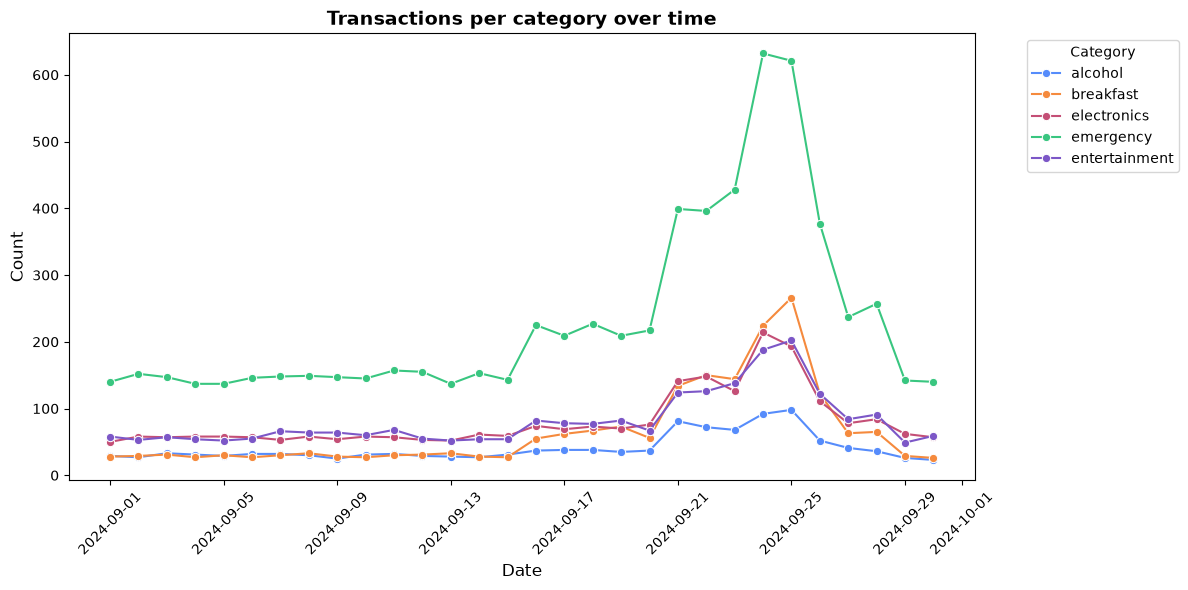

In [141]:
from matplotlib import pyplot as plt


top_5_categories = ["emergency", "breakfast", "electronics", "entertainment", "alcohol"]
df_filtered = df[df['category'].isin(top_5_categories)]
category_count = df_filtered.groupby(["date", "category"]).agg(
    count=('category', 'count')
).reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=category_count,
    x='date',
    y='count',
    hue='category',
    marker='o'
)

plt.title('Transactions per category over time', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()


**Q1 Answer:** The breakfast category's transactions experienced the greatest sales surge leading up to the hurricane's landfall. Emergency had the most transactions, but not the largest % jump.

### Question 2: The Pop-Tarts Effect (SKU Consolidation)

> After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

**Requires:** Building an SKU mapping table, consolidating fragmented products, side-by-side visualization (before vs. after cleaning), written analysis of business impact.

---

# Create SKU mapping

In [142]:
import pandas as pd
def create_mappings(from_list: list[str], to: str) -> dict[str, str]:
    d = {}
    for fr in from_list:
        d[fr] = to
    return d

CANON = {}
# |= merges dictionaries
CANON |= create_mappings(["SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
                         "PT-12")
CANON |= create_mappings(["WTR-24", "WATER24PK", "WTR_24PK"],
                         "WTR-24")
CANON |= create_mappings(['BG-MONO', 'MONOPOLY-01', 'GAME-MONO'],
                         'BG-MONO')
CANON |= create_mappings(['BEER-24', 'LTBEER24'],
                         'BEER-24')
CANON |= create_mappings(['BATT-100', 'BAT-AA4', 'BATT_AA_4PK' ],
                         'BATT-AA')
CANON |= create_mappings(['FLASH-01','LED-FLASH'],
                         'LED-FLASH')
CANON |= create_mappings(['CARDS-01','PLAYCARD-STD'],
                         'PLAYCARD-STD')
CANON |= create_mappings(['STREAM-01','ROKU-STD'],
                         'STREAM-01')
CANON |= create_mappings(['SOUP-CAN','CNSOUP-01',],
                         'CNSOUP-01')
CANON |= create_mappings(['BREAD-WH', 'WHITEBREAD'],
                         'BREAD-24')
CANON |= create_mappings(['PB-16' , 'PNUTBTR-16'],
                         'PB-16')
CANON |= create_mappings(['CNDL-EM' ,'CANDLE-EMRG'],
                         'CANDLE-EM' )
CANON |= create_mappings(['FAID-01', 'FIRSTAID-KIT'],
                         'FAID-01' )
CANON |= create_mappings(['CHRG-PORT' , 'PORTCHARGER'],
                         'CHRG-PORT' )
CANON |= create_mappings(['CHIPS-VP', 'CHIPVARIETY'],
                         'CHIPS-VP' )
CANON |= create_mappings(['PTOWEL-6', 'PAPERTOWEL6'],
                         'PTOWEL-6')
CANON |= create_mappings(['TP-12', 'TOILETPAPER12'],
                         'TP-12')
CANON |= create_mappings(['DIAP-S3', 'DIAPERS-3'],
                         'DIAP-S3')
CANON |= create_mappings(['BFORM-01', 'BABYFORMULA'],
                         'BFORM-01')
CANON |= create_mappings(['TARP-HD', 'HDTARP-01'],
                         'TARP-HD')


# Consolidate on the product catalog

In [143]:
df = pd.read_csv('../data/product_catalog.csv')

def consolidate(frame):
    out = frame.copy()
    out['canonical_sku'] = out.apply(apply_canonical_sku, axis=1)
    return out

def apply_canonical_sku(row):
    if row['sku'] in CANON:
        return CANON[row['sku']]
    return row['sku']

consolidated = consolidate(df)

consolidated

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack,PT-12
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk,PT-12
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack,PT-12
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack,PT-12
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack,WTR-24
5,WATER24PK,Bottled Water 24-Pack,Emergency,Bottled,2.38,Sara Lee,24 pack,WTR-24
6,WTR_24PK,Water - 24 Pack,Emergency,NaN,2.08,Frito-Lay,1 pack,WTR-24
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack,BATT-AA
8,BAT-AA4,AA Batteries 4-Pack,Emergency Supplies,AA,4.16,Kimberly-Clark,4pk,BATT-AA
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,AA,3.71,Anheuser-Busch,24 pack,BATT-AA


In [144]:
start_skus = df['sku'].nunique()
end_skus = consolidated['canonical_sku'].nunique()
print(f"Started with {start_skus} distinct SKUs and ended with {end_skus} canonical SKUs")

Started with 45 distinct SKUs and ended with 20 canonical SKUs


# Consolidate on the transaction log

In [145]:
consolidated_transactions = consolidate(cleaned_transactions)

original_units = cleaned_transactions['quantity'].sum()
new_units = consolidated_transactions['quantity'].sum()
assert original_units == new_units

consolidated_transactions

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date,canonical_sku
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,grocery,1,3.15,2024-09-24,PB-16
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,grocery,1,2.02,2024-09-13,CNSOUP-01
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,household,2,10.47,2024-09-17,TP-12
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,electronics,1,28.59,2024-09-11,STREAM-01
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,alcohol,3,18.82,2024-09-26,BEER-24
...,...,...,...,...,...,...,...,...,...,...
25557,TXN020201,FL-105,2024-09-03 18:28:07,DIAPERS-3,Diapers Size 3,baby,2,24.32,2024-09-03,DIAP-S3
25558,TXN014835,FL-239,2024-09-26 08:47:08,CARDS-01,Playing Cards,entertainment,3,5.00,2024-09-26,PLAYCARD-STD
25559,TXN002434,FL-239,2024-09-16 16:39:00,PAPERTOWEL6,Paper Towels 6-Roll,household,2,7.78,2024-09-16,PTOWEL-6
25560,TXN014739,FL-710,2024-09-25 17:08:35,CHRG-PORT,PORTABLE CHARGER,electronics,1,24.18,2024-09-25,CHRG-PORT


# Count old SKUs and new canonicals

In [146]:
#poptart transaction count for each sku
groupbySku = consolidated_transactions.groupby('sku').agg(
    count = ('sku', 'count')
).reset_index()
poptarts = ["SKU#459812", "POPTART-STRAW", "PT-12", "PT_STRAWBERRY"]

groupbySkuFiltered = groupbySku[groupbySku['sku'].isin(poptarts)]

#poptart transaction count for each canonical
groupbyCanonical = consolidated_transactions.groupby('canonical_sku').agg(
    count = ('canonical_sku', 'count')
).reset_index()

groupbyCanonicalFiltered = groupbyCanonical[groupbyCanonical['canonical_sku'].isin(poptarts)]

print(groupbySkuFiltered)
print(groupbyCanonicalFiltered)

              sku  count
29  POPTART-STRAW    503
31          PT-12    536
33  PT_STRAWBERRY    512
35     SKU#459812    502
   canonical_sku  count
14         PT-12   2053


# Bar chart

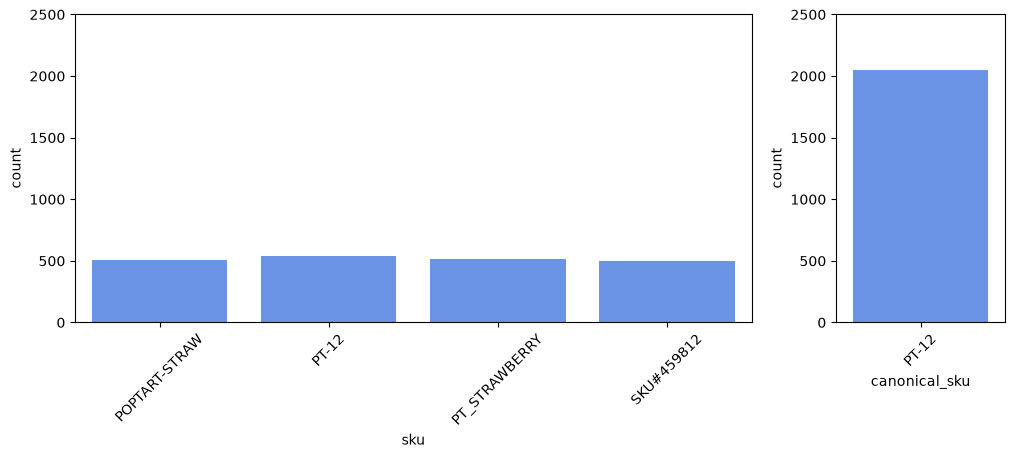

In [147]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(ncols=2,
                       figsize=(12, 4),
                       gridspec_kw={'width_ratios': [4, 1]})
sns.barplot(data = groupbySkuFiltered,x = 'sku', y = 'count', ax = ax[0])
sns.barplot(data = groupbyCanonicalFiltered,x = 'canonical_sku', y = 'count', ax = ax[1])
ax[0].set_ylim(0, 2500)
ax[1].set_ylim(0, 2500)
for a in ax:
    a.tick_params(axis='x', rotation=45)
plt.show()

**Q2 Answer:** The true daily sales volume after standardization is 2053. Upon first glance for fragmented sales is that it looks like there was around 500 sales for Pop-Tarts, and therefore not a good organization to determine the actual total sales for Pop-Tarts. With the cleaned/consolidated view, visually there is more sales above 2000 and cleaner to look at since all the sales are totaled. As for the business decision for consolidated, it would be encouraged to send more Pop-Tarts due to it's high sales compared to fragmented where the business would either keep it consistent or rescind Pop-Tart sales.

### Question 3: Weather Correlation Analysis

> Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

**Requires:** Weather API integration, timestamp/timezone alignment, correlation analysis (scatter plot, heatmap, or time-series overlay), lag analysis discussion.

---

# API call function

In [148]:
import time
import requests


BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'orlando fallback',
})

def daily_weather(start, end, lat, lon, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

# Attempt call...

In [149]:
try:
    weather_orlando = daily_weather('2024-09-01', '2024-09-30', lat=28.54, lon=-81.38)
except requests.RequestException as err:
    print('API call failed:', err)
    weather_orlando = FALLBACK

weather_orlando

,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source
0,2024-09-01,3.0,18.8,1014.1,open-meteo
1,2024-09-02,12.4,13.5,1014.1,open-meteo
2,2024-09-03,24.9,22.8,1015.7,open-meteo
3,2024-09-04,22.1,15.5,1017.8,open-meteo
4,2024-09-05,23.1,15.2,1017.3,open-meteo
5,2024-09-06,9.3,9.0,1014.3,open-meteo
6,2024-09-07,6.8,14.2,1011.9,open-meteo
7,2024-09-08,94.7,12.6,1013.8,open-meteo
8,2024-09-09,28.0,11.5,1015.7,open-meteo
9,2024-09-10,14.4,14.3,1014.3,open-meteo


# Grab category count data and join

In [150]:
category_count = cleaned_transactions.groupby(["date", "category"]).agg(
    transaction_count=('category', 'count')
).reset_index()

# merge

merged_df = pd.merge(category_count, weather_orlando, on='date', how='left', indicator=True)

print(merged_df['_merge'].value_counts())
print(f"Merged dataframe shape: {merged_df.shape}")

merged_df

_merge
both          300
left_only       0
right_only      0
Name: count, dtype: int64
Merged dataframe shape: (300, 8)


,date,category,transaction_count,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,_merge
0,2024-09-01,alcohol,29,3.0,18.8,1014.1,open-meteo,both
1,2024-09-01,baby,62,3.0,18.8,1014.1,open-meteo,both
2,2024-09-01,breakfast,28,3.0,18.8,1014.1,open-meteo,both
3,2024-09-01,electronics,50,3.0,18.8,1014.1,open-meteo,both
4,2024-09-01,emergency,140,3.0,18.8,1014.1,open-meteo,both
...,...,...,...,...,...,...,...,...
295,2024-09-30,entertainment,59,3.3,8.6,1013.8,open-meteo,both
296,2024-09-30,grocery,78,3.3,8.6,1013.8,open-meteo,both
297,2024-09-30,health,31,3.3,8.6,1013.8,open-meteo,both
298,2024-09-30,household,55,3.3,8.6,1013.8,open-meteo,both


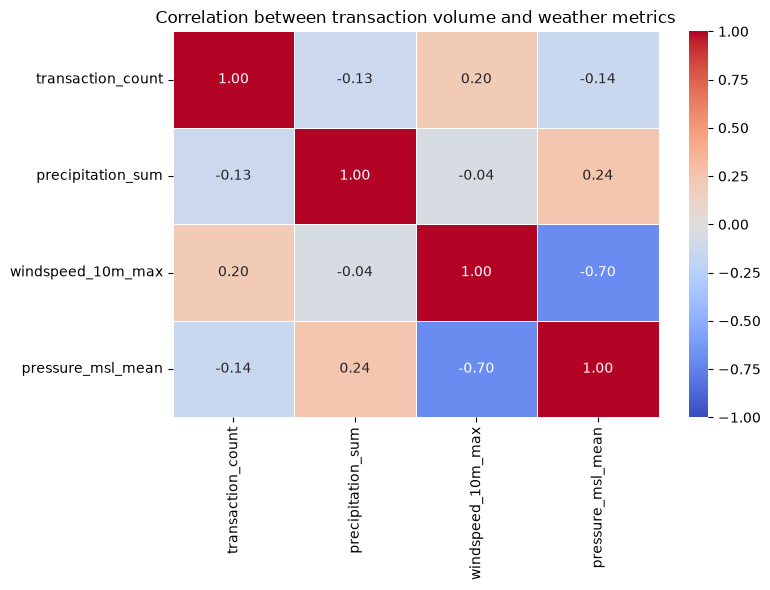

In [151]:
corr_cols = [
    'transaction_count',
    'precipitation_sum',
    'windspeed_10m_max',
    'pressure_msl_mean'
]

corr_matrix = merged_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True, cmap='coolwarm', fmt=".2f",
    vmin=-1, vmax=1, linewidths=0.5, ax=ax)

plt.title('Correlation between transaction volume and weather metrics')
plt.tight_layout()
plt.show()

Transaction data seems to only have a 0.20 correlation with the windspeed, and only -0.13 with precipitation_sum. What if we filter this to just before the storm?

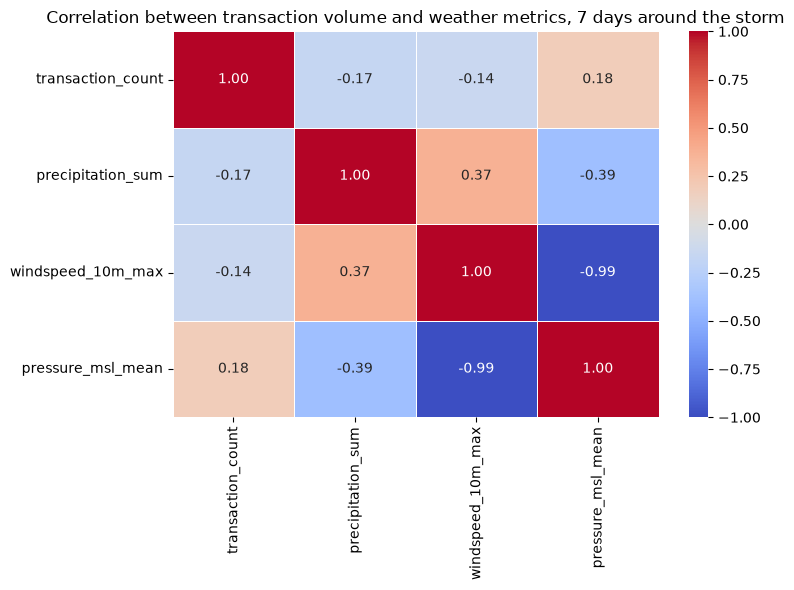

In [152]:
# Instead, filter on dates during the storm

target_start = pd.to_datetime('2024-09-22')
target_end = pd.to_datetime('2024-09-28')
target_dates = pd.date_range(start=target_start, end=target_end)

merged_df_storm = merged_df[merged_df['date'].isin(target_dates)]

corr_matrix = merged_df_storm[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True, cmap='coolwarm', fmt=".2f",
    vmin=-1, vmax=1, linewidths=0.5, ax=ax)

plt.title('Correlation between transaction volume and weather metrics, 7 days around the storm')
plt.tight_layout()
plt.show()

# Chart showing correlation between weather data and breakfast sales surge

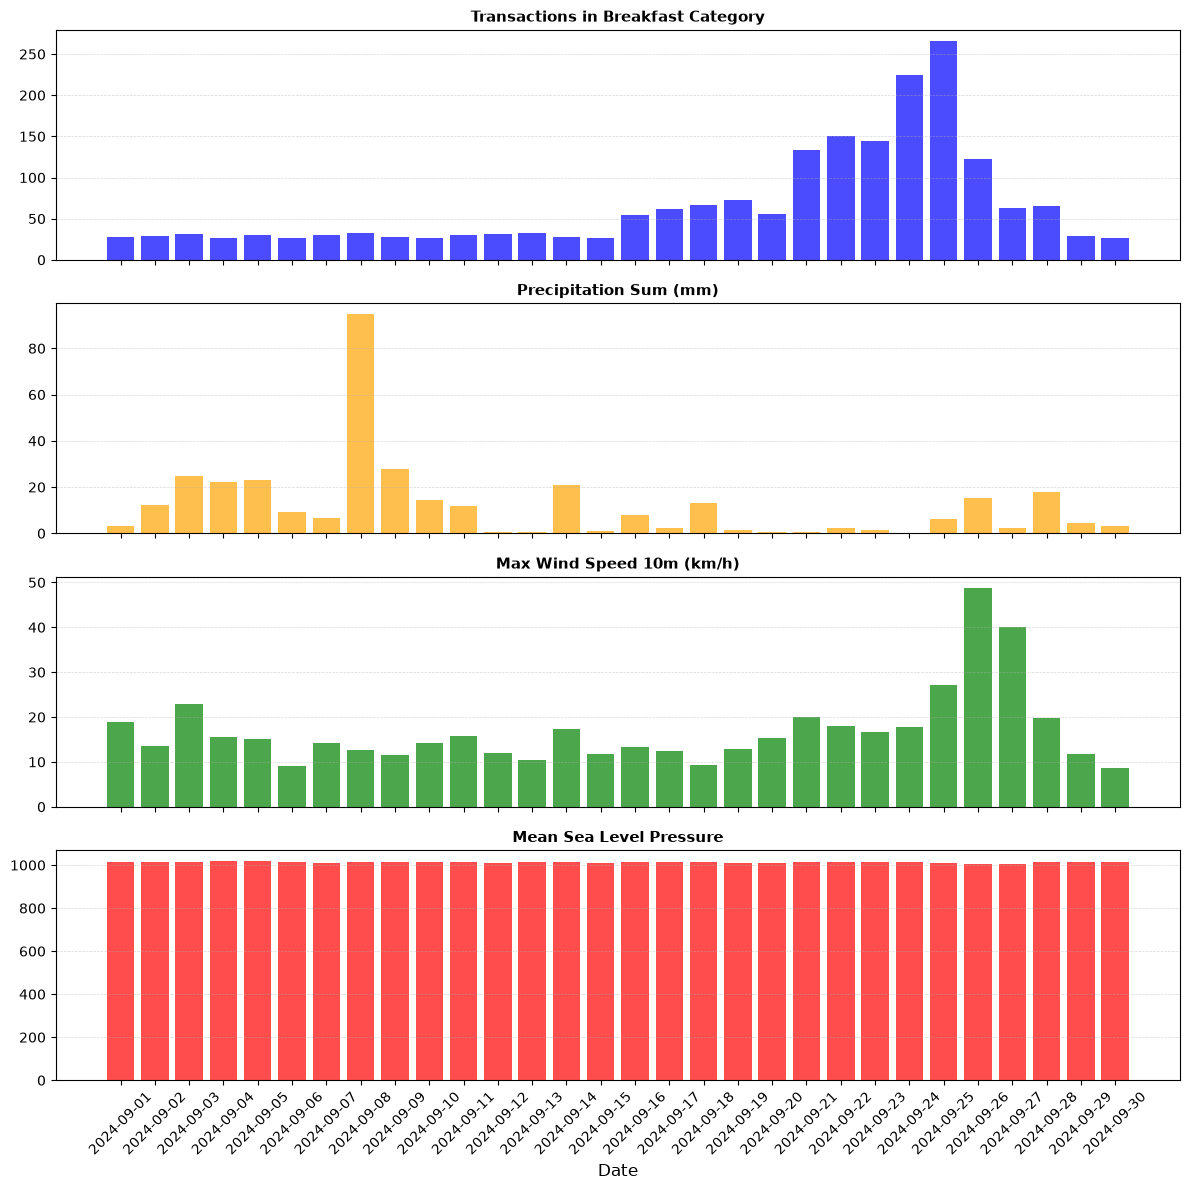

In [153]:
# Breakfast only
df_breakfast = merged_df[merged_df['category'] == 'breakfast'][[
    'date',
    'transaction_count',
    'precipitation_sum',
    'windspeed_10m_max',
    'pressure_msl_mean'
]].copy()

df_breakfast = df_breakfast.rename(columns={'transaction_count': 'breakfast_sales'})

dates_str = df_breakfast['date'].dt.strftime('%Y-%m-%d')

# chart

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)

metrics = [
    ('breakfast_sales', 'Transactions in Breakfast Category', 'blue'),
    ('precipitation_sum', 'Precipitation Sum (mm)', 'orange'),
    ('windspeed_10m_max', 'Max Wind Speed 10m (km/h)', 'green'),
    ('pressure_msl_mean', 'Mean Sea Level Pressure', 'red')
]

for i, (col, title, color) in enumerate(metrics):
    axes[i].bar(dates_str, df_breakfast[col], color=color, alpha=0.7)
    axes[i].set_title(title, fontsize=11, fontweight='bold')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.xlabel('Date', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Q3 Answer:** None of the weather metrics seem to be directly correlated with sales data. However, you can see the sales spike, and then the wind speed immediately spiking the day after. Sales were actually on the increase leading up to the storm. But on the day that there was high wind speed of 50kmh, sales immediately dipped. So there isn't a lag.

### Question 4: Store-Level Geographic Patterns

> Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

**Requires:** Joining store location data with transactions, geographic grouping, comparing surge timing and magnitude across stores, bar chart or grouped comparison, outlier identification.

---

Store Surge Summary:
store_id                            store_name    region  baseline_tx  max_tx   max_date  surge_ratio
  FL-302          Walmart Supercenter Lakeland   Central        50.93     200 2024-09-25         3.93
  FL-710         Walmart Supercenter Pensacola Panhandle        48.07     188 2024-09-25         3.91
  FL-445    Walmart Supercenter St. Petersburg      West        49.43     179 2024-09-24         3.62
  FL-105             Walmart Supercenter Tampa      West        47.50     170 2024-09-25         3.58
  FL-330             Walmart Supercenter Miami     South        46.00     163 2024-09-25         3.54
  FL-156     Walmart Supercenter Daytona Beach      East        48.00     168 2024-09-24         3.50
  FL-412      Walmart Supercenter Jacksonville     North        47.93     167 2024-09-24         3.48
  FL-078       Walmart Supercenter Gainesville     North        47.86     165 2024-09-25         3.45
  FL-287 Walmart Neighborhood Market Kissimmee   Central     

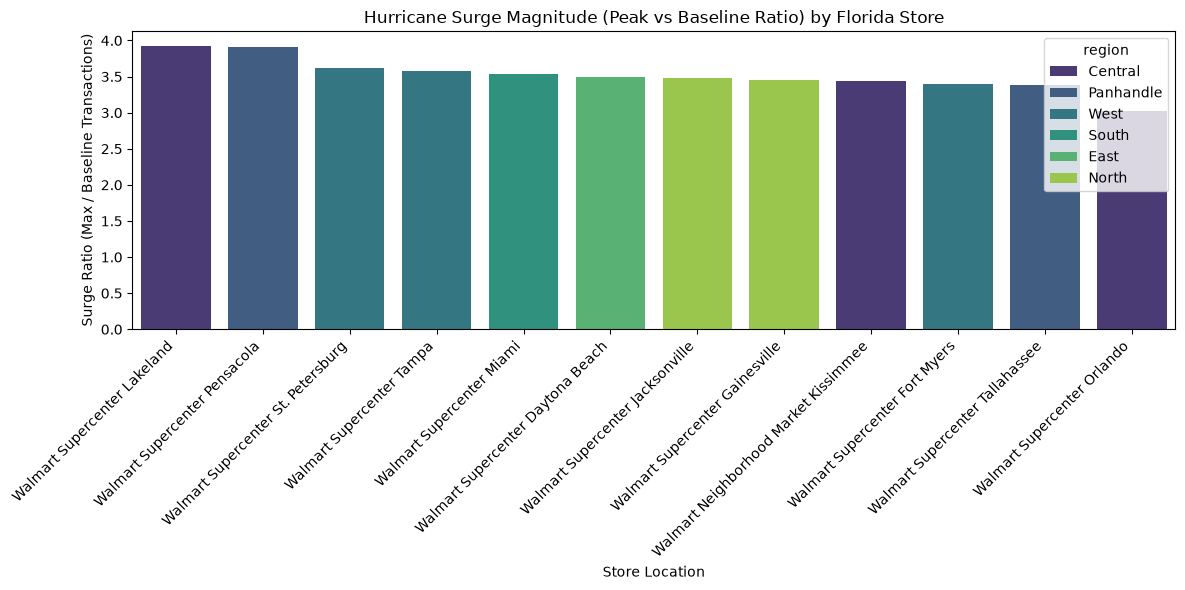

In [154]:
import sqlite3
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
trans = cleaned_transactions
stores = pd.read_csv('../data/store_locations.csv')
# cleaning data store locations
stores['store_id'] = stores['store_id'].str.replace('FL239', 'FL-239').str.replace('FL_287', 'FL-287')
stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
stores_clean = stores.drop_duplicates(subset=['store_id']).reset_index(drop=True)
stores_clean['region'] = stores_clean['region'].str.strip()


merged = trans.merge(stores_clean, on='store_id', how='left')
merged['timestamp'] = pd.to_datetime(merged['timestamp'], format='mixed')
merged['date'] = merged['timestamp'].dt.date
#group by store and date for geo surge analysis
store_daily = merged.dropna(subset=['date']).groupby(
    ['store_id', 'store_name', 'region', 'latitude', 'longitude', 'date']
).agg(
    tx_count=('transaction_id', 'count'),
    total_qty=('quantity', 'sum'),
    total_sales=('unit_price', lambda x: (x * merged.loc[x.index, 'quantity']).sum())
).reset_index()

# Calculate baseline (pre-surge, e.g., Sept 1-14) vs peak surge magnitude and timing
store_summary = []
for store_id, group in store_daily.groupby('store_id'):
    store_name = group['store_name'].iloc[0]
    region = group['region'].iloc[0]
    lat = group['latitude'].iloc[0]
    lon = group['longitude'].iloc[0]

    baseline_tx = group[group['date'] < pd.to_datetime('2024-09-15').date()]['tx_count'].mean()
    max_tx = group['tx_count'].max()
    max_date = str(group.loc[group['tx_count'].idxmax(), 'date'])
    surge_ratio = max_tx / baseline_tx if baseline_tx > 0 else np.nan

    store_summary.append({
        'store_id': store_id,
        'store_name': store_name,
        'region': region,
        'latitude': lat,
        'longitude': lon,
        'baseline_tx': round(baseline_tx, 2),
        'max_tx': int(max_tx),
        'max_date': max_date,
        'surge_ratio': round(surge_ratio, 2)
    })

summary_df = pd.DataFrame(store_summary).sort_values(by='surge_ratio', ascending=False)
print("Store Surge Summary:")
print(summary_df[['store_id', 'store_name', 'region', 'baseline_tx', 'max_tx', 'max_date', 'surge_ratio']].to_string(index=False))

# data viz
plt.figure(figsize=(12, 6))
sns.barplot(data=summary_df, x='store_name', y='surge_ratio', hue='region', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Hurricane Surge Magnitude (Peak vs Baseline Ratio) by Florida Store')
plt.xlabel('Store Location')
plt.ylabel('Surge Ratio (Max / Baseline Transactions)')
plt.tight_layout()
plt.show()

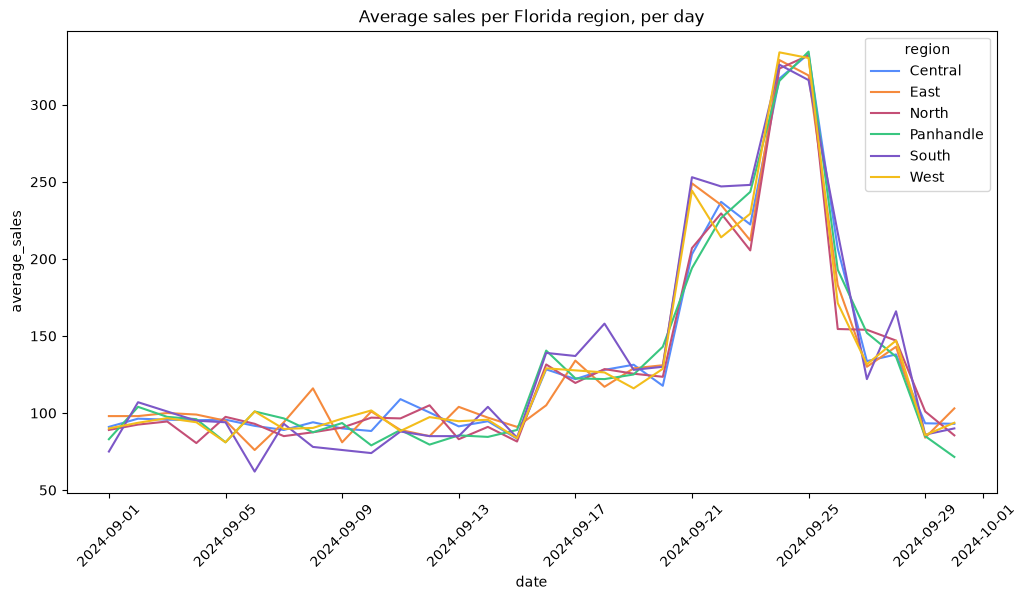

In [165]:
grouped = merged.groupby(['date', 'store_id']).agg(
    sales=('quantity', 'sum'),
    region=('region', 'first')
)

sales_by_region = grouped.groupby(['date', 'region']).agg(
    average_sales=('sales', 'mean')
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=sales_by_region, x='date', y='average_sales', hue='region', ax=ax)
plt.xticks(rotation=45)
ax.set_title("Average sales per Florida region, per day")
plt.show()

**Q4 Answer:**

Most follow similar surge patterns but there is a noticeable increase at the panhandle region specifically Pensacola and central region at lakeland. Panhandle and central were both in the predicated path for hurricane helene.

### Question 5: Signal vs. Artifact — The Board Games Investigation

> The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

**Requires:** Querying the SQLite database with `sqlite3` + `pandas`, cross-referencing with the transaction CSV, SKU/category audit, evidence-based written argument, supporting visualization.

---

# Pull SQL data and convert to dataframe

In [156]:
import sqlite3

connection = sqlite3.connect("../data/inventory_and_sales.db")

inventory_levels = pd.read_sql_query("SELECT * FROM inventory_levels", connection)
daily_sales_summary = pd.read_sql_query("SELECT * FROM daily_sales_summary", connection)
print(inventory_levels.head())
print(daily_sales_summary.head())

         date store_id          sku  units_on_hand  units_on_order  \
0  2024-09-12   FL-239     CHIPS-VP            112             5.0   
1  2024-09-12   FL-239  PAPERTOWEL6            106            46.0   
2  2024-09-12   FL-239        PT-12             62            36.0   
3  2024-09-12   FL-239  PORTCHARGER            185            62.0   
4  2024-09-12   FL-239     BFORM-01             88             1.0   

   reorder_point  
0             31  
1             36  
2             30  
3             40  
4             35  
         date store_id       category  total_units  total_revenue
0  2024-09-12   FL-239      Emergency         90.0        1582.55
1  2024-09-12   FL-239      Breakfast         57.0         356.99
2  2024-09-12   FL-239        Alcohol         41.0         246.65
3  2024-09-12   FL-239  Entertainment         53.0         916.56
4  2024-09-12   FL-239        Grocery         69.0         339.30


In [157]:
# Pull only entertainment transaction data

transactions_entertainment = consolidated_transactions[consolidated_transactions['category'] == 'entertainment']

transactions_entertainment

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,date,canonical_sku
10,TXN022661,FL-412,2024-09-07 17:22:06,CARDS-01,PLAYING CARDS,entertainment,2,4.76,2024-09-07,PLAYCARD-STD
14,TXN004265,FL-412,2024-09-18 08:12:08,CARDS-01,PLAYING CARDS,entertainment,2,5.15,2024-09-18,PLAYCARD-STD
42,TXN003444,FL-412,2024-09-17 18:22:08,CARDS-01,Standard Playing Cards,entertainment,3,4.79,2024-09-17,PLAYCARD-STD
61,TXN014923,FL-105,2024-09-26 13:40:00,PLAYCARD-STD,Playing Cards,entertainment,2,4.97,2024-09-26,PLAYCARD-STD
65,TXN016562,FL-619,2024-09-27 20:57:00,BG-MONO,Monopoly Board Game,entertainment,2,19.16,2024-09-27,BG-MONO
...,...,...,...,...,...,...,...,...,...,...
25506,TXN009515,FL-330,2024-09-23 22:00:08,GAME-MONO,Board Game - Monopoly,entertainment,1,19.62,2024-09-23,BG-MONO
25524,TXN003094,FL-302,2024-09-16 18:27:00,BG-MONO,Board Game - Monopoly,entertainment,1,20.89,2024-09-16,BG-MONO
25544,TXN010478,FL-302,2024-09-23 06:46:19,CARDS-01,PLAYING CARDS,entertainment,2,5.05,2024-09-23,PLAYCARD-STD
25555,TXN021715,FL-619,2024-09-05 13:13:40,PLAYCARD-STD,Playing Cards,entertainment,3,5.23,2024-09-05,PLAYCARD-STD


In [158]:
print(f"unique skus: {transactions_entertainment['sku'].unique()}")
entertainment_skus = transactions_entertainment['sku'].unique().to_numpy()
print(f"unique canonical skus: {transactions_entertainment['canonical_sku'].unique()}")

unique skus: <StringArray>
['CARDS-01', 'PLAYCARD-STD', 'BG-MONO', 'MONOPOLY-01', 'GAME-MONO']
Length: 5, dtype: str
unique canonical skus: <StringArray>
['PLAYCARD-STD', 'BG-MONO']
Length: 2, dtype: str


# Examine the stock of each SKU

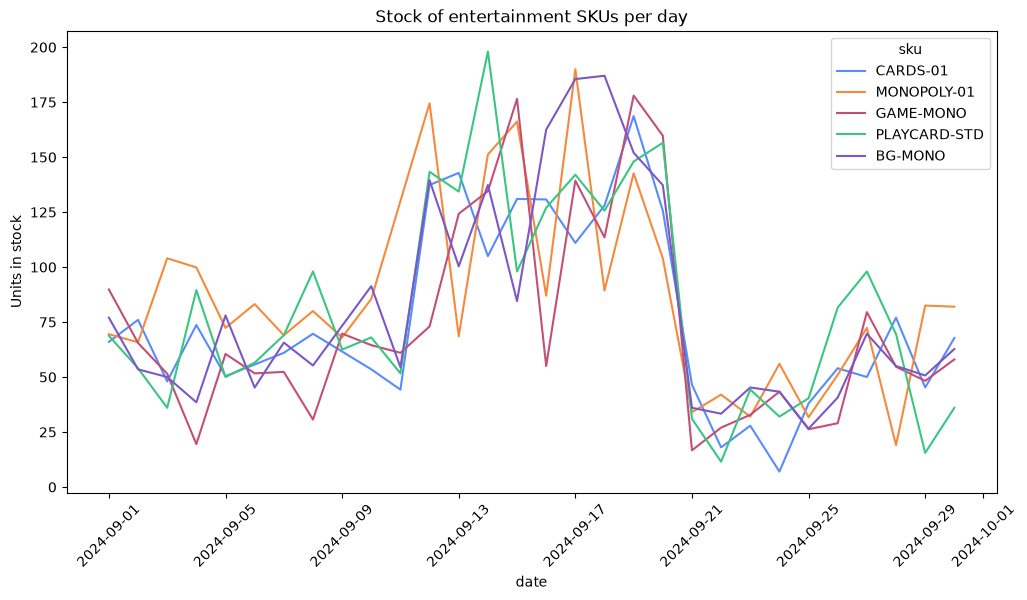

In [159]:
entertainment_stock = inventory_levels[inventory_levels['sku'].isin(entertainment_skus)]

# oops need to turn it into an actual date
entertainment_stock['date'] = pd.to_datetime(entertainment_stock['date'])
entertainment_stock = entertainment_stock.sort_values('date')

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(data=entertainment_stock, x='date', y='units_on_hand', hue='sku', errorbar=None, ax=ax)
plt.xticks(rotation=45)
ax.set_ylabel('Units in stock')
ax.set_title('Stock of entertainment SKUs per day')
plt.show()

# Examine the transactions per day on these SKUs from the CSV

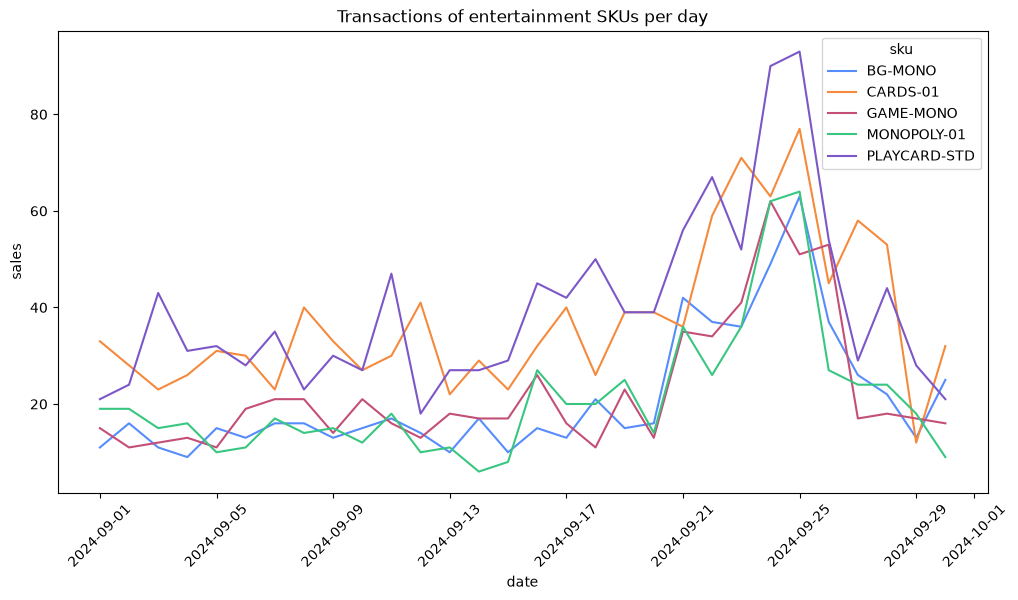

In [160]:
# group by day
entertainment_transactions_per_day = transactions_entertainment.groupby(['date', 'sku']).agg(
    sales=('quantity', 'sum')
)


fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(data=entertainment_transactions_per_day, x='date', y='sales', hue='sku', errorbar=None, ax=ax)
plt.xticks(rotation=45)
ax.set_title('Transactions of entertainment SKUs per day')
plt.show()

There's a drop in stock on the 21st, but the transaction surge is on the 25th. You can however see the transactions starting to surge slightly on the 21st.

# What about the daily sales summary from the database?

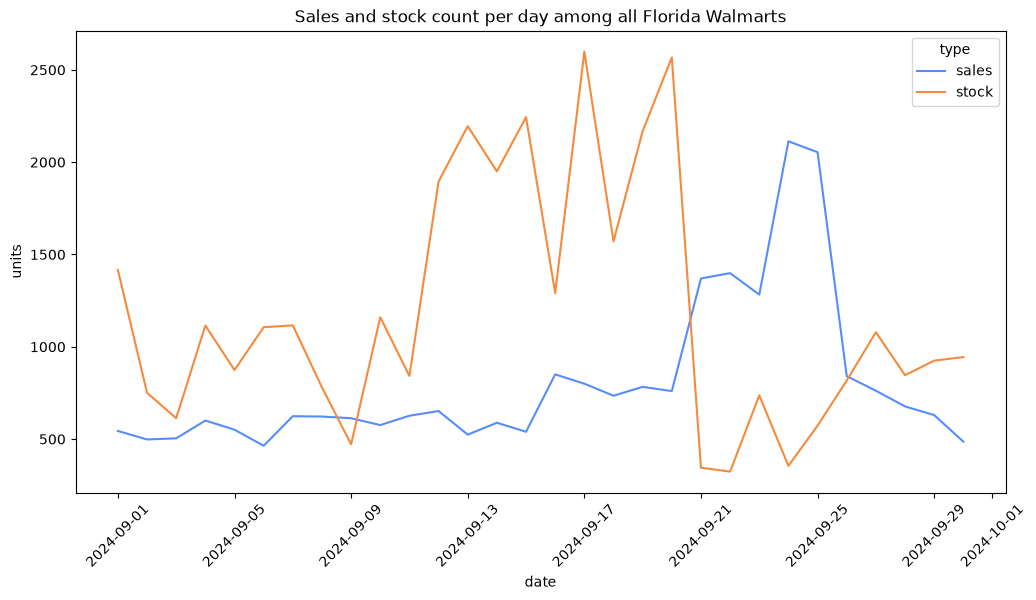

In [161]:
daily_sales_summary['date'] = pd.to_datetime(daily_sales_summary['date'], format='mixed')
entertainment_sales = daily_sales_summary[daily_sales_summary['category'] == "Entertainment"]
entertainment_sales = entertainment_sales.groupby('date').agg(
    sales=('total_units', 'sum')
)

entertainment_stock_per_day = entertainment_stock.groupby('date').agg(
    stock=('units_on_hand', 'sum')
)

merged_df = pd.merge(entertainment_sales, entertainment_stock_per_day, on='date', how='outer').reset_index()

long_df = pd.melt(merged_df, id_vars='date', value_vars=["sales", "stock"], value_name='units', var_name='type')

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(data=long_df, x='date', y='units', hue='type', errorbar=None, ax=ax)
plt.xticks(rotation=45)
ax.set_title('Sales and stock count per day among all Florida Walmarts')
plt.show()

**Q5 answer:** It seems like there was a genuine increase in demand for monopoly and card games during the hurricane. It was not an artifact, because you can clearly see a sharp decrease in stock and an increase in sales on the 21st. Does this mean that Walmart should continue to stock more entertainment products? Maybe, but I'm leaning towards not too many more, as long as it doesn't displace emergency supply space.